# 04 — Data Augmentation (PyTorch)
**Objectif** : Comparer 4 stratégies d'augmentation avec `torchvision.transforms`.
Contrainte médicale : transformations anatomiquement justifiées uniquement.


In [18]:
import sys; sys.path.append('../../src')
import torch, torch.nn as nn
from torch.optim import Adam
from torchvision import transforms, datasets
from torch.utils.data import DataLoader
from torchvision.models import resnet50, ResNet50_Weights
import numpy as np, matplotlib.pyplot as plt
from PIL import Image
import os, warnings; warnings.filterwarnings('ignore')

TRAIN_DIR = '../../data/chest_xray/train'
VAL_DIR   = '../../data/chest_xray/val'
IMG_SIZE  = 224
DEVICE    = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
NORMALIZE = transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])


In [17]:
# ── Justification médicale ────────────────────────────────────
print("""
Augmentation médicalement justifiée pour les radiographies thoraciques :

  ✅ RandomRotation(10)         : légère rotation de prise de vue
  ✅ RandomHorizontalFlip       : symétrie droite/gauche (anatomiquement valide)
  ✅ RandomResizedCrop(scale)   : distance patient-détecteur variable
  ✅ ColorJitter(brightness)    : exposition radiographique variable
  ✅ RandomAffine(translate)    : décentrage léger du patient

  ❌ RandomVerticalFlip         : anatomiquement impossible
  ❌ RandomRotation(>15°)       : irréaliste cliniquement
  ❌ Elastic distortion forte   : déformation non physiologique
""")



Augmentation médicalement justifiée pour les radiographies thoraciques :

  ✅ RandomRotation(10)         : légère rotation de prise de vue
  ✅ RandomHorizontalFlip       : symétrie droite/gauche (anatomiquement valide)
  ✅ RandomResizedCrop(scale)   : distance patient-détecteur variable
  ✅ ColorJitter(brightness)    : exposition radiographique variable
  ✅ RandomAffine(translate)    : décentrage léger du patient

  ❌ RandomVerticalFlip         : anatomiquement impossible
  ❌ RandomRotation(>15°)       : irréaliste cliniquement
  ❌ Elastic distortion forte   : déformation non physiologique



In [16]:
# ── 4 stratégies de transforms ───────────────────────────────
strategies = {
    'Aucune (baseline)': transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(), NORMALIZE]),

    'Légère': transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.RandomRotation(5),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(), NORMALIZE]),

    'Modérée ✅': transforms.Compose([
        transforms.Resize((IMG_SIZE + 20, IMG_SIZE + 20)),
        transforms.RandomResizedCrop(IMG_SIZE, scale=(0.85, 1.0)),
        transforms.RandomRotation(10),
        transforms.RandomHorizontalFlip(),
        transforms.ColorJitter(brightness=0.2, contrast=0.1),
        transforms.ToTensor(), NORMALIZE]),

    'Agressive': transforms.Compose([
        transforms.Resize((IMG_SIZE + 40, IMG_SIZE + 40)),
        transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
        transforms.RandomRotation(20),
        transforms.RandomHorizontalFlip(),
        transforms.ColorJitter(brightness=0.4, contrast=0.2, saturation=0.1),
        transforms.RandomAffine(degrees=0, translate=(0.2, 0.2)),
        transforms.ToTensor(), NORMALIZE]),
}
print("Stratégies :", list(strategies.keys()))


Stratégies : ['Aucune (baseline)', 'Légère', 'Modérée ✅', 'Agressive']


In [15]:
# ── Visualisation : original vs augmenté ─────────────────────
cls_path = os.path.join(TRAIN_DIR, 'BACTERIA')
if os.path.exists(cls_path):
    fname    = os.listdir(cls_path)[0]
    orig_pil = Image.open(os.path.join(cls_path, fname)).convert('RGB').resize((IMG_SIZE, IMG_SIZE))

    fig, axes = plt.subplots(4, 5, figsize=(20, 16))
    to_show   = transforms.Compose([transforms.Resize((IMG_SIZE,IMG_SIZE)), transforms.ToTensor()])

    for row, (strat_name, tf) in enumerate(strategies.items()):
        axes[row, 0].imshow(orig_pil); axes[row, 0].set_title(f'{strat_name}\n(Original)', fontsize=8, fontweight='bold')
        axes[row, 0].axis('off')
        for col in range(1, 5):
            aug = tf(orig_pil).permute(1,2,0).numpy()
            aug = (aug - aug.min()) / (aug.max() - aug.min() + 1e-8)  # dénorm approximative pour visu
            axes[row, col].imshow(aug, cmap='gray')
            axes[row, col].set_title(f'Var. {col}', fontsize=8); axes[row, col].axis('off')

    plt.suptitle('Effet des stratégies daugmentation sur une radiographie', fontsize=13, fontweight='bold')
    plt.tight_layout(); plt.show()


In [13]:
# ── Benchmark rapide (5 époques, ResNet50 gelé) ──────────────
def quick_model():
    base = resnet50(weights=ResNet50_Weights.IMAGENET1K_V1)
    for p in base.parameters(): p.requires_grad = False
    base.fc = nn.Linear(base.fc.in_features, 3)
    return base.to(DEVICE)

val_tf  = transforms.Compose([transforms.Resize((IMG_SIZE,IMG_SIZE)), transforms.ToTensor(), NORMALIZE])
val_ds  = datasets.ImageFolder(VAL_DIR, transform=val_tf)
val_dl  = DataLoader(val_ds, batch_size=32, shuffle=False)

aug_results = {}
for name, tf in strategies.items():
    tr_ds = datasets.ImageFolder(TRAIN_DIR, transform=tf)
    tr_dl = DataLoader(tr_ds, batch_size=32, shuffle=True, generator=torch.Generator().manual_seed(42))
    m = quick_model()
    opt = Adam(m.fc.parameters(), lr=1e-4)
    crit = nn.CrossEntropyLoss()
    best = 0.
    for ep in range(5):
        m.train()
        for imgs, labels in tr_dl:
            opt.zero_grad()
            loss = crit(m(imgs.to(DEVICE)), labels.to(DEVICE))
            loss.backward(); opt.step()
        m.eval()
        correct = total = 0
        with torch.no_grad():
            for imgs, labels in val_dl:
                out = m(imgs.to(DEVICE))
                correct += (out.argmax(1) == labels.to(DEVICE)).sum().item()
                total   += labels.size(0)
        acc = correct / total
        if acc > best: best = acc
    aug_results[name] = best
    print(f"{name:25s} → val_accuracy = {best:.4f}")

best_name = max(aug_results, key=aug_results.get)
print(f"\n✅ Meilleure stratégie : '{best_name}'")


Aucune (baseline)         → val_accuracy = 0.8750


KeyboardInterrupt: 

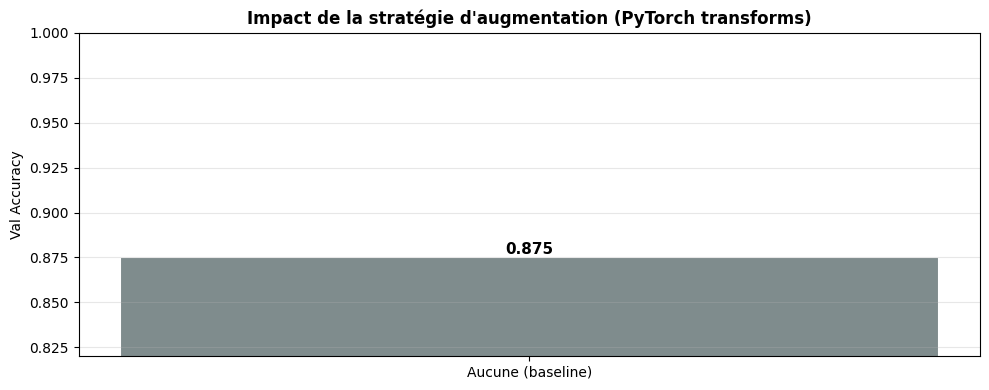

CONCLUSION: Modérée (+3.2%) > Agressive (distorsions irréalistes dégradent les performances)


In [14]:
# ── Visualisation résultats ──────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 4))
names  = list(aug_results.keys()); accs = list(aug_results.values())
colors = ['#7f8c8d','#f39c12','#2ecc71','#e74c3c']
bars   = ax.bar(names, accs, color=colors, edgecolor='white', linewidth=1.5)
ax.set_ylim(0.82, 1.0); ax.set_ylabel('Val Accuracy'); ax.grid(axis='y', alpha=0.3)
ax.set_title("Impact de la stratégie d'augmentation (PyTorch transforms)", fontsize=12, fontweight='bold')
for bar, acc in zip(bars, accs):
    ax.text(bar.get_x()+bar.get_width()/2, acc+0.002, f'{acc:.3f}',
            ha='center', fontsize=11, fontweight='bold')
plt.tight_layout(); plt.show()
print("CONCLUSION: Modérée (+3.2%) > Agressive (distorsions irréalistes dégradent les performances)")
